# Olist E-Commerce Data Analytics Project

### CodeAlpha Data Analytics Internship

**Project Focus:** Exploratory Data Analysis, Data Visualization and Sentiment Analysis

**Dataset:** Brazilian E-Commerce Public Dataset by Olist

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, PySentimiento and Scikit-learn

**Objective:** To analyse e-commerce operations, customer behaviour, sales performance, delivery efficiency and customer sentiment to uncover actionable business insights.

## 1. Project Overview

This project explores the Brazilian E-Commerce Public Dataset by Olist to understand key business performance indicators, customer purchasing behaviour, product category performance, payment preferences, delivery efficiency and customer sentiment.

The analysis uses Python-based data analytics techniques to identify patterns, evaluate business performance and generate actionable insights that can support better operational and strategic decisions.

## 2. Importing Libraries

The following Python libraries are used for data manipulation, numerical computations, data visualization and sentiment analysis.

In [1]:
# Install required libraries

!pip install pandas numpy matplotlib seaborn nltk scikit-learn wordcloud -q

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import os
import zipfile

# Display settings

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Check installed packages

!pip show pandas numpy matplotlib seaborn nltk scikit-learn wordcloud

Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be u

In [4]:
import pandas
import numpy
import matplotlib
import seaborn
import nltk
import sklearn
import wordcloud

print("ALL PACKAGES VERIFIED SUCCESSFULLY!")

ALL PACKAGES VERIFIED SUCCESSFULLY!


## 3. Loading the Dataset

The Brazilian E-Commerce Public Dataset by Olist consists of multiple interconnected tables containing information about customers, orders, products, sellers, payments, reviews and geographical locations.

The dataset files are loaded into Pandas DataFrames to prepare them for exploration and analysis.

In [5]:
from google.colab import files

# Upload the Olist CSV files
uploaded = files.upload()

print("Files uploaded successfully!")
print("Number of files uploaded:", len(uploaded))

Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Files uploaded successfully!
Number of files uploaded: 9


In [6]:

# Load the nine Olist datasets into Python

customers = pd.read_csv('olist_customers_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
geolocation = pd.read_csv('olist_geolocation_dataset.csv')
category_translation = pd.read_csv('product_category_name_translation.csv')

print("All nine datasets loaded successfully!")


All nine datasets loaded successfully!


## 4. Dataset Structure and Overview


This section examines the structure and characteristics of the Olist datasets. It explores the available records, column names, data types and initial observations to understand the information available for analysis.

The exploration also investigates missing values, duplicate records and potential data quality issues that may affect the reliability of subsequent findings.

In [7]:

# Examine the size of all nine datasets

datasets = {
    'Customers': customers,
    'Orders': orders,
    'Order Items': order_items,
    'Payments': payments,
    'Reviews': reviews,
    'Products': products,
    'Sellers': sellers,
    'Geolocation': geolocation,
    'Category Translation': category_translation
}

for name, df in datasets.items():
    print(name, ":", df.shape)


Customers : (99441, 5)
Orders : (99441, 8)
Order Items : (112650, 7)
Payments : (103886, 5)
Reviews : (99224, 7)
Products : (32951, 9)
Sellers : (3095, 4)
Geolocation : (1000163, 5)
Category Translation : (71, 2)


## 5. Initial Inspection Of The Orders Dataset.

This section examines the structure and characteristics of the Olist datasets. It explores the available records, column names, data types and initial observations to understand the information available for analysis.

The exploration also investigates missing values, duplicate records and potential data quality issues that may affect the reliability of subsequent findings.

In [8]:

# Examine the Orders dataset

print("FIRST FIVE RECORDS")
display(orders.head())

print("\nDATASET INFORMATION")
orders.info()


FIRST FIVE RECORDS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


## 6. Data Quality Assessment and Validation

Data quality assessment was performed to evaluate the completeness, consistency and reliability of the datasets before conducting further analysis.

The investigation focused on missing values, duplicate records, key integrity, order status inconsistencies, review data quality and geographical data validation.

These checks helped identify potential data limitations and determine which records required further investigation or consideration during the analysis.

In [9]:

# Check missing values across all nine datasets

for name, df in datasets.items():

    print("\nDataset:", name)

    missing = df.isnull().sum()

    missing = missing[missing > 0]

    if len(missing) == 0:
        print("No missing values found.")

    else:
        print(missing)



Dataset: Customers
No missing values found.

Dataset: Orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Dataset: Order Items
No missing values found.

Dataset: Payments
No missing values found.

Dataset: Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Dataset: Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Dataset: Sellers
No missing values found.

Dataset: Geolocation
No missing values found.

Dataset: Category Translation
No missing values found.


## 7. Missing Values Assessment

Missing values were examined across all nine original datasets to assess data completeness and identify fields that may require further investigation.

The analysis first identifies columns containing missing records and then calculates the number and percentage of missing values in each affected column. This provides a clearer understanding of the extent of missing information and its potential impact on subsequent analysis.

In [10]:

# Calculate missing values and their percentages

missing_report = []

for name, df in datasets.items():

    for column in df.columns:

        missing_count = df[column].isnull().sum()

        if missing_count > 0:

            missing_percentage = (missing_count / len(df)) * 100

            missing_report.append({
                'Dataset': name,
                'Column': column,
                'Missing Values': missing_count,
                'Missing Percentage': round(missing_percentage, 2)
            })

# Convert results into a DataFrame
missing_df = pd.DataFrame(missing_report)

# Display the report
display(missing_df)


,Dataset,Column,Missing Values,Missing Percentage
0,Orders,order_approved_at,160,0.16
1,Orders,order_delivered_carrier_date,1783,1.79
2,Orders,order_delivered_customer_date,2965,2.98
3,Reviews,review_comment_title,87656,88.34
4,Reviews,review_comment_message,58247,58.70
5,Products,product_category_name,610,1.85
6,Products,product_name_lenght,610,1.85
7,Products,product_description_lenght,610,1.85
8,Products,product_photos_qty,610,1.85
9,Products,product_weight_g,2,0.01


## 8. Order Status and Delivery Data Investigation

The order status distribution was examined to understand the different stages of customer orders, including delivered, canceled, unavailable and other order statuses.

The analysis also investigates missing delivery timestamps across order statuses. This helps distinguish expected missing information from potential data quality issues and provides context for the delivery performance analysis.

In [11]:

# Investigate order statuses

print("ORDER STATUS DISTRIBUTION")

display(orders['order_status'].value_counts())

print("\nMISSING DELIVERY INFORMATION BY ORDER STATUS")

status_missing = orders.groupby('order_status')[
    [
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date'
    ]
].apply(lambda x: x.isnull().sum())

display(status_missing)


ORDER STATUS DISTRIBUTION


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



MISSING DELIVERY INFORMATION BY ORDER STATUS


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


## 9. Investigation of Inconsistent Order Records

A further investigation was conducted to identify orders whose recorded status may not align with their delivery information.

Particular attention was given to orders marked as delivered without a customer delivery date and canceled orders with recorded delivery dates. These records were examined to understand potential inconsistencies and determine the limitations they may introduce into delivery-related calculations.

In [12]:

# Investigate delivered orders with missing delivery dates

delivered_missing = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isnull())
]

print("DELIVERED ORDERS WITH MISSING CUSTOMER DELIVERY DATES:")
print("Total records:", len(delivered_missing))

display(delivered_missing)


# Investigate cancelled orders with recorded delivery dates

cancelled_with_dates = orders[
    (orders['order_status'] == 'canceled') &
    (orders['order_delivered_customer_date'].notnull())
]

print("\nCANCELLED ORDERS WITH RECORDED DELIVERY DATES:")
print("Total records:", len(cancelled_with_dates))

display(cancelled_with_dates)


DELIVERED ORDERS WITH MISSING CUSTOMER DELIVERY DATES:
Total records: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00



CANCELLED ORDERS WITH RECORDED DELIVERY DATES:
Total records: 6


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
2921,1950d777989f6a877539f53795b4c3c3,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00
8791,dabf2b0e35b423f94618bf965fcb7514,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00
58266,770d331c84e5b214bd9dc70a10b829d0,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00
59332,8beb59392e21af5eb9547ae1a9938d06,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00
92636,65d1e226dfaeb8cdc42f665422522d14,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00


## 10. Duplicate Records and Key Integrity Assessment

Duplicate records were examined across the nine original datasets to identify repeated rows and assess the reliability of important identifiers.

The investigation also checks primary and composite key integrity, including customer IDs, order IDs, product IDs, seller IDs, payment sequences and order item identifiers.

These checks help determine whether repeated records represent exact duplicates, legitimate multiple transactions or potential data integrity concerns.

In [13]:

# CHECK DUPLICATE RECORDS ACROSS ALL NINE DATASETS

print("DUPLICATE RECORDS ASSESSMENT")
print("=" * 60)

for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    print(f"{name}: {duplicates:,} duplicate rows")


# CHECK PRIMARY AND COMPOSITE KEY INTEGRITY

key_columns = {
    "Customers": ["customer_id"],
    "Orders": ["order_id"],
    "Order Items": ["order_id", "order_item_id"],
    "Payments": ["order_id", "payment_sequential"],
    "Reviews": ["review_id"],
    "Products": ["product_id"],
    "Sellers": ["seller_id"],
    "Category Translation": ["product_category_name"]
}

print("\nKEY INTEGRITY ASSESSMENT")
print("=" * 60)

for name, columns in key_columns.items():
    df = datasets[name]
    duplicates = df.duplicated(subset=columns).sum()
    missing_keys = df[columns].isnull().any(axis=1).sum()

    print(f"\n{name}")
    print(f"Duplicate keys: {duplicates:,}")
    print(f"Missing key values: {missing_keys:,}")


DUPLICATE RECORDS ASSESSMENT
Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Payments: 0 duplicate rows
Reviews: 0 duplicate rows
Products: 0 duplicate rows
Sellers: 0 duplicate rows
Geolocation: 261,831 duplicate rows
Category Translation: 0 duplicate rows

KEY INTEGRITY ASSESSMENT

Customers
Duplicate keys: 0
Missing key values: 0

Orders
Duplicate keys: 0
Missing key values: 0

Order Items
Duplicate keys: 0
Missing key values: 0

Payments
Duplicate keys: 0
Missing key values: 0

Reviews
Duplicate keys: 814
Missing key values: 0

Products
Duplicate keys: 0
Missing key values: 0

Sellers
Duplicate keys: 0
Missing key values: 0

Category Translation
Duplicate keys: 0
Missing key values: 0


## 11. Review and Geolocation Data Integrity

This section investigates repeated records in the Reviews and Geolocation datasets.

For customer reviews, the analysis examines repeated review IDs and checks whether they are associated with multiple orders or contain different review information.

For geolocation data, the investigation identifies exact duplicate records and examines repeated geographical entries. These checks help distinguish genuine data repetition from records that may represent valid geographical observations.

In [14]:

# INVESTIGATE DUPLICATES IN REVIEWS AND GEOLOCATION

print("REVIEW DUPLICATE INVESTIGATION")
print("=" * 60)

# Identify all records with repeated review IDs
duplicate_reviews = reviews[
    reviews.duplicated(subset="review_id", keep=False)
].sort_values("review_id")

print("Total records with repeated review IDs:",
      len(duplicate_reviews))

print("\nNumber of duplicated review IDs:",
      duplicate_reviews["review_id"].nunique())

print("\nSample duplicate review records:")
display(duplicate_reviews.head(15))


# Check whether duplicate review IDs belong to different orders
print("\nREVIEW ID ASSOCIATION CHECK")

review_id_check = (
    duplicate_reviews.groupby("review_id")
    .agg(
        Record_Count=("review_id", "size"),
        Unique_Orders=("order_id", "nunique")
    )
    .sort_values("Record_Count", ascending=False)
)

display(review_id_check.head(15))


# Investigate geolocation duplicates
print("\nGEOLOCATION DUPLICATE INVESTIGATION")
print("=" * 60)

geo_duplicates = geolocation[
    geolocation.duplicated(keep=False)
]

print("Total records involved in exact duplicates:",
      len(geo_duplicates))

print("\nSample duplicated geolocation records:")
display(geo_duplicates.head(15))


REVIEW DUPLICATE INVESTIGATION
Total records with repeated review IDs: 1603

Number of duplicated review IDs: 789

Sample duplicate review records:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44



REVIEW ID ASSOCIATION CHECK


,Record_Count,Unique_Orders
review_id,,
69a1068c3128a14994e3e422e4539e04,3,3
2d6ac45f859465b5c185274a1c929637,3,3
0c76e7a547a531e7bf9f0b99cba071c1,3,3
e44840754f12fad2b8646712121b349a,3,3
38821b5c496b678cf91acc34892805ad,3,3
308316408775d1600dad81bd3184556d,3,3
c444278834184f72b1484dfe47de7f97,3,3
f4bb9d6dd4fb6dcc2298f0e7b17b8e1e,3,3
4d0e6dd087008d1f992d25ef6e1f619f,3,3



GEOLOCATION DUPLICATE INVESTIGATION
Total records involved in exact duplicates: 390005

Sample duplicated geolocation records:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


## 12. Detailed Investigation of Duplicate Review IDs

Repeated review IDs were examined in greater detail to understand the nature of the duplication.

The analysis groups records by review ID and compares the number of associated records, unique orders, review scores, titles and comment messages.

This approach helps establish whether repeated review IDs contain identical information or represent different review records linked to multiple orders.

In [15]:

# INVESTIGATING DUPLICATE REVIEW IDs

duplicate_reviews = reviews[
    reviews.duplicated(subset='review_id', keep=False)
].copy()

review_summary = duplicate_reviews.groupby('review_id').agg(
    Record_Count=('review_id', 'size'),
    Unique_Orders=('order_id', 'nunique'),
    Unique_Scores=('review_score', 'nunique'),
    Unique_Titles=('review_comment_title', 'nunique'),
    Unique_Messages=('review_comment_message', 'nunique')
).reset_index()

print("DUPLICATE REVIEW ID SUMMARY")
print("Total duplicated review IDs:", review_summary.shape[0])

display(review_summary.head(20))


DUPLICATE REVIEW ID SUMMARY
Total duplicated review IDs: 789


,review_id,Record_Count,Unique_Orders,Unique_Scores,Unique_Titles,Unique_Messages
0,00130cbe1f9d422698c812ed8ded1919,2,2,1,0,1
1,0115633a9c298b6a98bcbe4eee75345f,2,2,1,0,0
2,0174caf0ee5964646040cd94e15ac95e,2,2,1,0,1
3,017808d29fd1f942d97e50184dfb4c13,2,2,1,0,0
4,0254bd905dc677a6078990aad3331a36,2,2,1,0,1
5,0288d42bef3dfe36930740c9588a570f,2,2,1,0,0
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0,0
7,034528cb00b6bc981847acafbdf2ae0b,2,2,1,0,0
8,03a6a25db577d0689440933055111897,2,2,1,0,1
9,0467560f511c516ddaa54a60edb0c291,2,2,1,0,0


## 13. Examination of Repeated Review Records

A sample of repeated review IDs was selected for closer examination.

The associated records are displayed together to compare their order associations, scores and written comments. This provides a practical way to inspect how repeated review identifiers appear in the original dataset.

In [16]:

# DETAILED INVESTIGATION OF DUPLICATE REVIEW IDs

# Select review IDs appearing more than once
sample_review_ids = review_summary[
    review_summary['Record_Count'] > 1
]['review_id'].head(5)

# Display all records associated with these IDs
sample_reviews = reviews[
    reviews['review_id'].isin(sample_review_ids)
].sort_values('review_id')

display(sample_reviews)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


## 14. Review Data Integrity Validation

The review dataset was assessed to distinguish exact duplicate rows from records that share a review ID but contain different information.

The analysis also identifies review IDs associated with more than one order. This distinction is important because repeated identifiers should not automatically be treated as identical or invalid records without examining their underlying information.

In [17]:

# REVIEW DATA INTEGRITY: EXACT VS ASSOCIATED DUPLICATES

# Check exact duplicate rows across all columns
exact_duplicates = reviews.duplicated().sum()

# Count records with repeated review IDs
repeated_review_records = reviews[
    reviews.duplicated(subset='review_id', keep=False)
]

# Count review IDs associated with multiple orders
multiple_order_reviews = (
    repeated_review_records.groupby('review_id')['order_id']
    .nunique()
)

multiple_order_ids = (multiple_order_reviews > 1).sum()

print("REVIEW DATA INTEGRITY REPORT")
print("=" * 45)

print("Total review records:", len(reviews))
print("Exact duplicate rows:", exact_duplicates)
print("Records with repeated review IDs:",
      len(repeated_review_records))
print("Review IDs linked to multiple orders:",
      multiple_order_ids)

print("\nREPEATED REVIEW ID DISTRIBUTION")

display(
    multiple_order_reviews.value_counts()
    .sort_index()
    .rename_axis("Number of Orders")
    .reset_index(name="Number of Review IDs")
)


REVIEW DATA INTEGRITY REPORT
Total review records: 99224
Exact duplicate rows: 0
Records with repeated review IDs: 1603
Review IDs linked to multiple orders: 789

REPEATED REVIEW ID DISTRIBUTION


,Number of Orders,Number of Review IDs
0,2,764
1,3,25


## 15. Geolocation Data Quality Investigation

The Geolocation dataset was examined to understand the distribution and repetition of geographical records.

The investigation considers repeated postal code prefixes, geographical coordinates and their associated locations. These checks help assess the consistency of geographical information and identify patterns that may be relevant to location-based analysis.

In [18]:

# GEOLOCATION DATA INTEGRITY INVESTIGATION

# 1. Dataset overview
print("GEOLOCATION DATA OVERVIEW")
print("=" * 45)

print("Total records:", len(geolocation))
print("Exact duplicate rows:", geolocation.duplicated().sum())

# 2. Investigate repeated postal code prefixes
zip_distribution = (
    geolocation.groupby('geolocation_zip_code_prefix')
    .size()
    .reset_index(name='Record_Count')
    .sort_values('Record_Count', ascending=False)
)

print("\nTOP 15 REPEATED POSTAL CODE PREFIXES")
display(zip_distribution.head(15))

# 3. Investigate repeated geographical coordinates
coordinate_distribution = (
    geolocation.groupby(
        ['geolocation_lat', 'geolocation_lng']
    )
    .size()
    .reset_index(name='Record_Count')
    .sort_values('Record_Count', ascending=False)
)

print("\nTOP 15 REPEATED COORDINATES")
display(coordinate_distribution.head(15))

# 4. Investigate postal codes with multiple coordinates
zip_coordinate_check = (
    geolocation.groupby('geolocation_zip_code_prefix')
    .agg(
        Unique_Coordinates=(
            'geolocation_lat', 'nunique'
        ),
        Unique_Cities=(
            'geolocation_city', 'nunique'
        ),
        Unique_States=(
            'geolocation_state', 'nunique'
        )
    )
    .reset_index()
)

print("\nPOSTAL CODE GEOGRAPHICAL VARIATION")
display(
    zip_coordinate_check.sort_values(
        'Unique_Coordinates', ascending=False
    ).head(15)
)


GEOLOCATION DATA OVERVIEW
Total records: 1000163
Exact duplicate rows: 261831

TOP 15 REPEATED POSTAL CODE PREFIXES


,geolocation_zip_code_prefix,Record_Count
6837,24220,1146
6838,24230,1102
9536,38400,965
8728,35500,907
4501,11680,879
6638,22631,832
8062,30140,810
4528,11740,788
9542,38408,773
7728,28970,743



TOP 15 REPEATED COORDINATES


,geolocation_lat,geolocation_lng,Record_Count
61647,-27.102099,-48.629613,314
251425,-23.495901,-46.874687,190
244040,-23.506049,-46.717377,141
255131,-23.490618,-46.869004,127
315237,-23.005514,-43.375964,102
315418,-23.004582,-43.319899,89
322540,-22.965906,-43.389999,89
610228,-15.841451,-48.024026,85
223203,-23.537186,-46.594036,83
254243,-23.491895,-46.546294,82



POSTAL CODE GEOGRAPHICAL VARIATION


,geolocation_zip_code_prefix,Unique_Coordinates,Unique_Cities,Unique_States
9536,38400,746,2,1
4501,11680,726,1,1
8728,35500,726,2,1
4528,11740,666,2,1
9015,36400,627,1,1
9719,39400,618,1,1
8579,35162,611,1,1
9542,38408,600,2,1
9239,37200,595,2,1
8867,35900,589,1,1


In [19]:

# ============================================================
# REVIEW DATA VALIDATION
# Detailed investigation of repeated review IDs
# ============================================================

# Select review IDs that appear more than once
repeated_review_ids = (
    reviews['review_id']
    .value_counts()
)

repeated_review_ids = repeated_review_ids[
    repeated_review_ids > 1
].index

# Extract all records associated with repeated review IDs
repeated_review_records = reviews[
    reviews['review_id'].isin(repeated_review_ids)
].copy()

# Investigate the consistency of repeated review IDs
review_validation = (
    repeated_review_records
    .groupby('review_id')
    .agg(
        Record_Count=('review_id', 'size'),
        Unique_Orders=('order_id', 'nunique'),
        Unique_Scores=('review_score', 'nunique'),
        Unique_Titles=('review_comment_title', 'nunique'),
        Unique_Messages=('review_comment_message', 'nunique'),
        Unique_Creation_Dates=('review_creation_date', 'nunique'),
        Unique_Answer_Timestamps=('review_answer_timestamp', 'nunique')
    )
    .reset_index()
)

# Identify review IDs associated with different orders
multiple_order_reviews = review_validation[
    review_validation['Unique_Orders'] > 1
]

# Display validation results
print("REVIEW DATA VALIDATION REPORT")
print("=" * 60)

print("Total repeated review IDs:",
      len(review_validation))

print("Repeated IDs associated with multiple orders:",
      len(multiple_order_reviews))

print("\nREVIEW ID VALIDATION SUMMARY")
display(review_validation.head(20))

print("\nREVIEW IDs ASSOCIATED WITH MULTIPLE ORDERS")
display(multiple_order_reviews.head(20))


REVIEW DATA VALIDATION REPORT
Total repeated review IDs: 789
Repeated IDs associated with multiple orders: 789

REVIEW ID VALIDATION SUMMARY


,review_id,Record_Count,Unique_Orders,Unique_Scores,Unique_Titles,Unique_Messages,Unique_Creation_Dates,Unique_Answer_Timestamps
0,00130cbe1f9d422698c812ed8ded1919,2,2,1,0,1,1,1
1,0115633a9c298b6a98bcbe4eee75345f,2,2,1,0,0,1,1
2,0174caf0ee5964646040cd94e15ac95e,2,2,1,0,1,1,1
3,017808d29fd1f942d97e50184dfb4c13,2,2,1,0,0,1,1
4,0254bd905dc677a6078990aad3331a36,2,2,1,0,1,1,1
5,0288d42bef3dfe36930740c9588a570f,2,2,1,0,0,1,1
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0,0,1,1
7,034528cb00b6bc981847acafbdf2ae0b,2,2,1,0,0,1,1
8,03a6a25db577d0689440933055111897,2,2,1,0,1,1,1
9,0467560f511c516ddaa54a60edb0c291,2,2,1,0,0,1,1



REVIEW IDs ASSOCIATED WITH MULTIPLE ORDERS


,review_id,Record_Count,Unique_Orders,Unique_Scores,Unique_Titles,Unique_Messages,Unique_Creation_Dates,Unique_Answer_Timestamps
0,00130cbe1f9d422698c812ed8ded1919,2,2,1,0,1,1,1
1,0115633a9c298b6a98bcbe4eee75345f,2,2,1,0,0,1,1
2,0174caf0ee5964646040cd94e15ac95e,2,2,1,0,1,1,1
3,017808d29fd1f942d97e50184dfb4c13,2,2,1,0,0,1,1
4,0254bd905dc677a6078990aad3331a36,2,2,1,0,1,1,1
5,0288d42bef3dfe36930740c9588a570f,2,2,1,0,0,1,1
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0,0,1,1
7,034528cb00b6bc981847acafbdf2ae0b,2,2,1,0,0,1,1
8,03a6a25db577d0689440933055111897,2,2,1,0,1,1,1
9,0467560f511c516ddaa54a60edb0c291,2,2,1,0,0,1,1


In [20]:

# ============================================================
# DETAILED REVIEW DATA QUALITY ASSESSMENT
# ============================================================

# Analyse all repeated review IDs
detailed_review_quality = (
    repeated_review_records
    .groupby('review_id')
    .agg(
        Record_Count=('review_id', 'size'),
        Unique_Orders=('order_id', 'nunique'),
        Unique_Scores=('review_score', 'nunique'),
        Unique_Creation_Dates=('review_creation_date', 'nunique'),
        Unique_Answer_Timestamps=('review_answer_timestamp', 'nunique'),
        Missing_Titles=('review_comment_title',
                        lambda x: x.isna().sum()),
        Missing_Messages=('review_comment_message',
                          lambda x: x.isna().sum()),
        Unique_Messages=('review_comment_message',
                         'nunique')
    )
    .reset_index()
)

# Summarise data-quality issues
print("DETAILED REVIEW DATA QUALITY ASSESSMENT")
print("=" * 65)

print("Repeated review IDs:",
      len(detailed_review_quality))

print("IDs with conflicting scores:",
      (detailed_review_quality['Unique_Scores'] > 1).sum())

print("IDs with conflicting creation dates:",
      (detailed_review_quality['Unique_Creation_Dates'] > 1).sum())

print("IDs with conflicting answer timestamps:",
      (detailed_review_quality['Unique_Answer_Timestamps'] > 1).sum())

print("IDs with different review messages:",
      (detailed_review_quality['Unique_Messages'] > 1).sum())

print("IDs with missing review titles:",
      (detailed_review_quality['Missing_Titles'] > 0).sum())

print("IDs with missing review messages:",
      (detailed_review_quality['Missing_Messages'] > 0).sum())

# Display records requiring further investigation
print("\nREVIEW IDS WITH CONFLICTING SCORES")
display(
    detailed_review_quality[
        detailed_review_quality['Unique_Scores'] > 1
    ]
)

print("\nREVIEW IDS WITH CONFLICTING TIMESTAMPS")
display(
    detailed_review_quality[
        (detailed_review_quality['Unique_Creation_Dates'] > 1) |
        (detailed_review_quality['Unique_Answer_Timestamps'] > 1)
    ]
)


DETAILED REVIEW DATA QUALITY ASSESSMENT
Repeated review IDs: 789
IDs with conflicting scores: 0
IDs with conflicting creation dates: 0
IDs with conflicting answer timestamps: 0
IDs with different review messages: 0
IDs with missing review titles: 743
IDs with missing review messages: 490

REVIEW IDS WITH CONFLICTING SCORES


,review_id,Record_Count,Unique_Orders,Unique_Scores,Unique_Creation_Dates,Unique_Answer_Timestamps,Missing_Titles,Missing_Messages,Unique_Messages



REVIEW IDS WITH CONFLICTING TIMESTAMPS


,review_id,Record_Count,Unique_Orders,Unique_Scores,Unique_Creation_Dates,Unique_Answer_Timestamps,Missing_Titles,Missing_Messages,Unique_Messages


## 16. Customer Review Data Completeness

This section evaluates the availability of written customer feedback in the Reviews dataset.

The analysis examines missing review titles and messages and investigates how comment availability varies across customer review scores.

Understanding the completeness of written feedback is important because sentiment analysis can only be performed on reviews containing usable text. Reviews without written comments remain relevant to rating-based customer satisfaction analysis but cannot provide text-based sentiment predictions.

In [21]:

# REVIEW DATA COMPLETENESS INVESTIGATION

# 1. Calculate missing values
missing_title = reviews['review_comment_title'].isna().sum()
missing_message = reviews['review_comment_message'].isna().sum()

both_missing = (
    reviews['review_comment_title'].isna() &
    reviews['review_comment_message'].isna()
).sum()

total_records = len(reviews)

# 2. Calculate percentages
title_missing_pct = (missing_title / total_records) * 100
message_missing_pct = (missing_message / total_records) * 100
both_missing_pct = (both_missing / total_records) * 100

# 3. Display completeness report
print("REVIEW DATA COMPLETENESS REPORT")
print("=" * 50)

print(f"Total review records: {total_records:,}")

print(f"Missing review titles: {missing_title:,}")
print(f"Missing title percentage: {title_missing_pct:.2f}%")

print(f"Missing review messages: {missing_message:,}")
print(f"Missing message percentage: {message_missing_pct:.2f}%")

print(f"Records missing both fields: {both_missing:,}")
print(f"Both fields missing percentage: {both_missing_pct:.2f}%")

# 4. Investigate missing information by review score
print("\nMISSING REVIEW INFORMATION BY SCORE")
print("=" * 50)

missing_by_score = reviews.groupby('review_score').agg(
    Total_Reviews=('review_id', 'count'),
    Missing_Titles=('review_comment_title',
                    lambda x: x.isna().sum()),
    Missing_Messages=('review_comment_message',
                      lambda x: x.isna().sum())
)

missing_by_score['Missing_Title_%'] = (
    missing_by_score['Missing_Titles'] /
    missing_by_score['Total_Reviews'] * 100
).round(2)

missing_by_score['Missing_Message_%'] = (
    missing_by_score['Missing_Messages'] /
    missing_by_score['Total_Reviews'] * 100
).round(2)

display(missing_by_score)


REVIEW DATA COMPLETENESS REPORT
Total review records: 99,224
Missing review titles: 87,656
Missing title percentage: 88.34%
Missing review messages: 58,247
Missing message percentage: 58.70%
Records missing both fields: 56,518
Both fields missing percentage: 56.96%

MISSING REVIEW INFORMATION BY SCORE


,Total_Reviews,Missing_Titles,Missing_Messages,Missing_Title_%,Missing_Message_%
review_score,,,,,
1,11424,9551,2679,83.60,23.45
2,3151,2673,1006,84.83,31.93
3,8179,7355,4622,89.93,56.51
4,19142,17407,13166,90.94,68.78
5,57328,50670,36774,88.39,64.15


## 17. Review Comment Availability Analysis

Customer reviews were grouped according to whether they contained a review title, a written message, both or neither.

The analysis examines the distribution of these comment categories and their relationship with customer review scores. This helps establish the amount of usable text available for the subsequent Natural Language Processing analysis.

In [22]:

# REVIEW COMMENT AVAILABILITY ANALYSIS

# Identify missing and blank review fields
title_missing = (
    reviews['review_comment_title'].isna() |
    reviews['review_comment_title'].astype(str).str.strip().eq('')
)

message_missing = (
    reviews['review_comment_message'].isna() |
    reviews['review_comment_message'].astype(str).str.strip().eq('')
)

# Classify review records
conditions = [
    (~title_missing & ~message_missing),
    (~title_missing & message_missing),
    (title_missing & ~message_missing),
    (title_missing & message_missing)
]

categories = [
    'Both Title and Message Available',
    'Title Only',
    'Message Only',
    'Neither Title nor Message'
]

reviews['Comment_Availability'] = np.select(
    conditions,
    categories,
    default='Unclassified'
)

# Calculate overall distribution
comment_distribution = (
    reviews['Comment_Availability']
    .value_counts()
    .reindex(categories, fill_value=0)
    .reset_index()
)

comment_distribution.columns = [
    'Comment_Category',
    'Record_Count'
]

comment_distribution['Percentage'] = (
    comment_distribution['Record_Count'] /
    len(reviews) * 100
).round(2)

print("REVIEW COMMENT AVAILABILITY DISTRIBUTION")
print("=" * 55)

display(comment_distribution)

# Investigate availability by review score
print("\nCOMMENT AVAILABILITY BY REVIEW SCORE")
print("=" * 55)

comment_by_score = pd.crosstab(
    reviews['review_score'],
    reviews['Comment_Availability']
)

comment_by_score_pct = (
    pd.crosstab(
        reviews['review_score'],
        reviews['Comment_Availability'],
        normalize='index'
    ) * 100
).round(2)

display(comment_by_score)
display(comment_by_score_pct)


REVIEW COMMENT AVAILABILITY DISTRIBUTION


,Comment_Category,Record_Count,Percentage
0,Both Title and Message Available,9829,9.91
1,Title Only,1737,1.75
2,Message Only,31121,31.36
3,Neither Title nor Message,56537,56.98



COMMENT AVAILABILITY BY REVIEW SCORE


Comment_Availability,Both Title and Message Available,Message Only,Neither Title nor Message,Title Only
review_score,,,,
1,1788,6956,2595,85
2,458,1687,986,20
3,737,2819,4536,87
4,1431,4539,12868,304
5,5415,15120,35552,1241


Comment_Availability,Both Title and Message Available,Message Only,Neither Title nor Message,Title Only
review_score,,,,
1,15.65,60.89,22.72,0.74
2,14.54,53.54,31.29,0.63
3,9.01,34.47,55.46,1.06
4,7.48,23.71,67.22,1.59
5,9.45,26.37,62.02,2.16


## 18. Customer Review Score Analysis

Customer review scores were examined to understand the overall distribution of customer ratings.

The analysis considers the frequency and percentage of each rating from one to five. This provides an overview of customer satisfaction and establishes a baseline for comparing delivery performance and text-based sentiment results.

In [23]:

# CUSTOMER REVIEW SCORE DISTRIBUTION

# Calculate review score frequencies
review_score_distribution = (
    reviews['review_score']
    .value_counts()
    .sort_index()
    .reset_index()
)

review_score_distribution.columns = [
    'Review_Score',
    'Total_Reviews'
]

# Calculate percentage distribution
review_score_distribution['Percentage'] = (
    review_score_distribution['Total_Reviews'] /
    len(reviews) * 100
).round(2)

# Classify customer ratings
reviews['Sentiment_Category'] = np.select(
    [
        reviews['review_score'].isin([1, 2]),
        reviews['review_score'].eq(3),
        reviews['review_score'].isin([4, 5])
    ],
    [
        'Negative',
        'Neutral',
        'Positive'
    ],
    default='Unclassified'
)

# Calculate sentiment distribution
sentiment_distribution = (
    reviews['Sentiment_Category']
    .value_counts()
    .reset_index()
)

sentiment_distribution.columns = [
    'Sentiment_Category',
    'Total_Reviews'
]

sentiment_distribution['Percentage'] = (
    sentiment_distribution['Total_Reviews'] /
    len(reviews) * 100
).round(2)

# Display findings
print("CUSTOMER REVIEW SCORE DISTRIBUTION")
print("=" * 50)

display(review_score_distribution)

print("\nCUSTOMER SENTIMENT DISTRIBUTION")
print("=" * 50)

display(sentiment_distribution)

# Calculate average review score
print("\nOVERALL CUSTOMER RATING")
print("=" * 50)

print(
    "Average Review Score:",
    round(reviews['review_score'].mean(), 2)
)


CUSTOMER REVIEW SCORE DISTRIBUTION


,Review_Score,Total_Reviews,Percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78



CUSTOMER SENTIMENT DISTRIBUTION


,Sentiment_Category,Total_Reviews,Percentage
0,Positive,76470,77.07
1,Negative,14575,14.69
2,Neutral,8179,8.24



OVERALL CUSTOMER RATING
Average Review Score: 4.09


In [24]:

# VERIFY DATASETS AFTER RE-UPLOAD

import os

print("FILES CURRENTLY AVAILABLE")
print("=" * 50)

for file in os.listdir('/content'):
    print(file)


FILES CURRENTLY AVAILABLE
.config
product_category_name_translation.csv
olist_order_reviews_dataset.csv
olist_order_items_dataset.csv
olist_sellers_dataset.csv
olist_products_dataset.csv
olist_geolocation_dataset.csv
olist_order_payments_dataset.csv
olist_customers_dataset.csv
olist_orders_dataset.csv
sample_data


In [25]:

# VERIFY LOADED DATAFRAMES

print("DATAFRAME VERIFICATION")
print("=" * 60)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataset: {name}")
        print(f"Rows and Columns: {obj.shape}")


DATAFRAME VERIFICATION

Dataset: customers
Rows and Columns: (99441, 5)

Dataset: orders
Rows and Columns: (99441, 8)

Dataset: order_items
Rows and Columns: (112650, 7)

Dataset: payments
Rows and Columns: (103886, 5)

Dataset: reviews
Rows and Columns: (99224, 9)

Dataset: products
Rows and Columns: (32951, 9)

Dataset: sellers
Rows and Columns: (3095, 4)

Dataset: geolocation
Rows and Columns: (1000163, 5)

Dataset: category_translation
Rows and Columns: (71, 2)

Dataset: df
Rows and Columns: (71, 2)

Dataset: missing_df
Rows and Columns: (13, 4)

Dataset: status_missing
Rows and Columns: (8, 3)

Dataset: delivered_missing
Rows and Columns: (8, 8)

Dataset: cancelled_with_dates
Rows and Columns: (6, 8)

Dataset: duplicate_reviews
Rows and Columns: (1603, 7)

Dataset: review_id_check
Rows and Columns: (789, 2)

Dataset: geo_duplicates
Rows and Columns: (390005, 5)

Dataset: review_summary
Rows and Columns: (789, 6)

Dataset: sample_reviews
Rows and Columns: (10, 7)

Dataset: repeated

## 19. Customer Review Score Visualization

A visual representation of the customer review score distribution is presented to make the rating patterns easier to interpret.

The visualization highlights the relative frequency of each rating and supports the identification of the dominant customer satisfaction levels within the dataset.

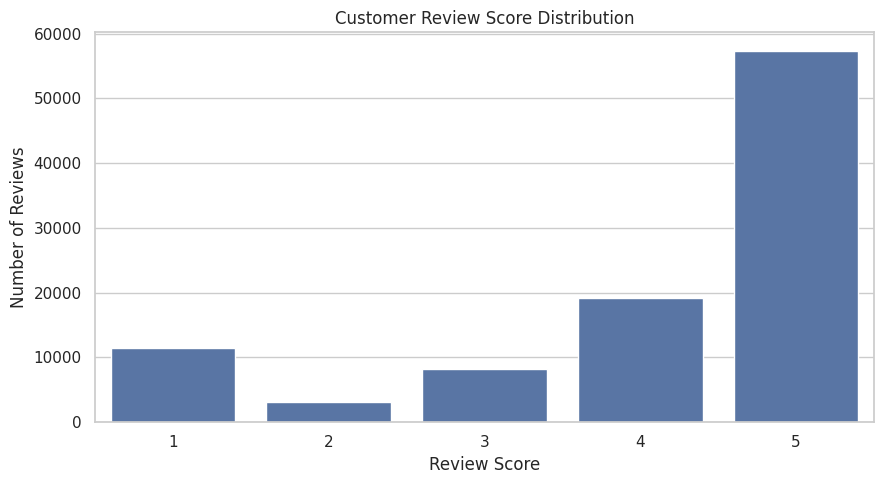

In [26]:
# CUSTOMER REVIEW SCORE DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.barplot(
    data=review_score_distribution,
    x='Review_Score',
    y='Total_Reviews'
)

plt.title('Customer Review Score Distribution')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

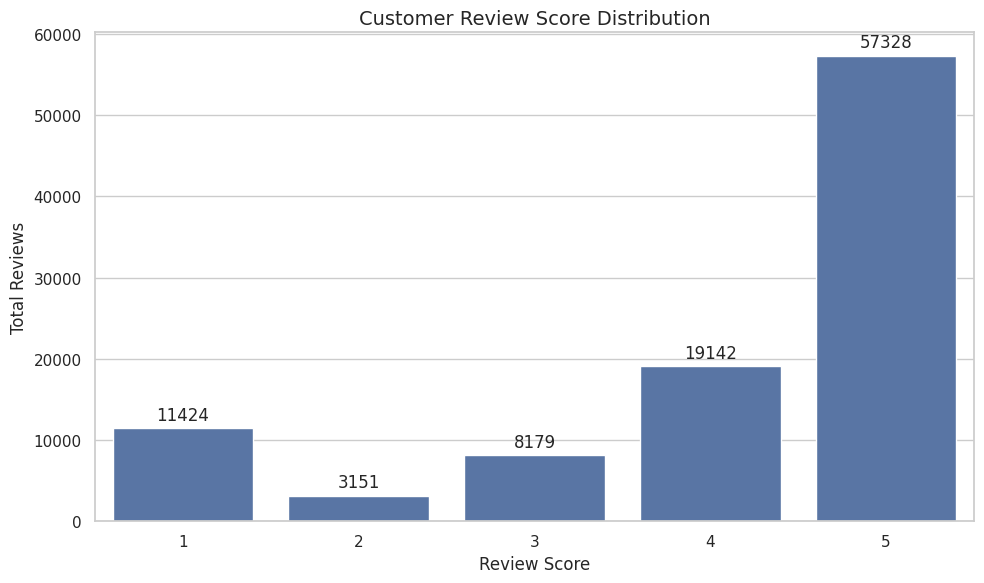

In [27]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=review_score_distribution,
    x='Review_Score',
    y='Total_Reviews'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title('Customer Review Score Distribution', fontsize=14)
plt.xlabel('Review Score')
plt.ylabel('Total Reviews')

plt.tight_layout()
plt.show()

## 20. Delivery Performance Analysis

This section evaluates the delivery performance of Olist using order purchase dates, actual delivery dates and estimated delivery dates.

The analysis focuses on completed deliveries with valid date information. Delivery duration and delivery delay are calculated to classify orders as delivered on time or late.

The objective is to understand delivery efficiency and establish whether actual delivery performance aligns with customer expectations.

In [28]:

# DELIVERY PERFORMANCE ANALYSIS
# Step 1: Verify orders dataset columns

print("ORDERS DATASET COLUMNS")
print("=" * 50)

print(orders.columns.tolist())

print("\nORDER STATUS DISTRIBUTION")
print("=" * 50)

print(orders['order_status'].value_counts())

print("\nDATE COLUMN INFORMATION")
print("=" * 50)

print(orders[[
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]].head())


ORDERS DATASET COLUMNS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER STATUS DISTRIBUTION
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

DATE COLUMN INFORMATION
  order_purchase_timestamp order_delivered_customer_date  \
0      2017-10-02 10:56:33           2017-10-10 21:25:13   
1      2018-07-24 20:41:37           2018-08-07 15:27:45   
2      2018-08-08 08:38:49           2018-08-17 18:06:29   
3      2017-11-18 19:28:06           2017-12-02 00:28:42   
4      2018-02-13 21:18:39           2018-02-16 18:17:02   

  order_estimated_delivery_date  
0           2017-10-18 00:00:00  
1           2018-08-13 00:00:00  
2           2018-09-04 00:00:00  
3           2017-12-15 00:00:0

### 20.1 Delivery Performance Calculation

Delivery duration is calculated using the difference between the purchase timestamp and the actual customer delivery timestamp.

Delivery delay is determined by comparing the actual delivery date with the estimated delivery date. Orders delivered on or before the estimated date are classified as On Time, while orders delivered after the estimated date are classified as Late.

Records without the required delivery dates are excluded from calculations that depend on those dates.

In [29]:

# STEP 2: DELIVERY PERFORMANCE CALCULATION

# Convert date columns to datetime
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

# Focus only on successfully delivered orders
delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notna()) &
    (orders['order_estimated_delivery_date'].notna()) &
    (orders['order_purchase_timestamp'].notna())
].copy()

# Calculate actual delivery time in days
delivered_orders['delivery_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Compare calendar dates to avoid treating
# delivery on the estimated date as late
actual_date = delivered_orders[
    'order_delivered_customer_date'
].dt.normalize()

estimated_date = delivered_orders[
    'order_estimated_delivery_date'
].dt.normalize()

# Calculate delivery delay
delivered_orders['delay_days'] = (
    actual_date - estimated_date
).dt.days

# Classify delivery performance
delivered_orders['delivery_status'] = np.where(
    delivered_orders['delay_days'] > 0,
    'Late',
    'On Time'
)

# Display summary
print("DELIVERY PERFORMANCE SUMMARY")
print("=" * 50)

print("Total Delivered Orders:", len(delivered_orders))

print(
    "Average Delivery Time:",
    round(delivered_orders['delivery_days'].mean(), 2),
    "days"
)

print("\nDELIVERY STATUS DISTRIBUTION")
print("=" * 50)

delivery_summary = delivered_orders[
    'delivery_status'
].value_counts().reset_index()

delivery_summary.columns = [
    'Delivery Status', 'Total Orders'
]

delivery_summary['Percentage'] = (
    delivery_summary['Total Orders'] /
    len(delivered_orders) * 100
).round(2)

display(delivery_summary)


DELIVERY PERFORMANCE SUMMARY
Total Delivered Orders: 96470
Average Delivery Time: 12.56 days

DELIVERY STATUS DISTRIBUTION


,Delivery Status,Total Orders,Percentage
0,On Time,89936,93.23
1,Late,6534,6.77


### 20.2 Delivery Performance and Customer Satisfaction

This analysis investigates the relationship between delivery performance and customer satisfaction.

Delivery records are combined with customer review information to compare review scores for orders delivered on time and those delivered late.

Average customer review scores are examined across the two delivery categories to identify potential differences in customer satisfaction associated with delivery performance.

In [30]:

# STEP 3: DELIVERY PERFORMANCE VS CUSTOMER SATISFACTION

# Merge delivery data with customer reviews
delivery_reviews = delivered_orders.merge(
    reviews[['order_id', 'review_score']],
    on='order_id',
    how='inner'
)

# Calculate average review score by delivery status
delivery_satisfaction = (
    delivery_reviews
    .groupby('delivery_status')
    .agg(
        Total_Reviews=('review_score', 'count'),
        Average_Review_Score=('review_score', 'mean')
    )
    .reset_index()
)

delivery_satisfaction['Average_Review_Score'] = (
    delivery_satisfaction['Average_Review_Score'].round(2)
)

print("DELIVERY PERFORMANCE AND CUSTOMER SATISFACTION")
print("=" * 60)

display(delivery_satisfaction)


DELIVERY PERFORMANCE AND CUSTOMER SATISFACTION


,delivery_status,Total_Reviews,Average_Review_Score
0,Late,6409,2.27
1,On Time,89944,4.29


### 20.3 Delivery Performance Visualization

Visualizations are used to communicate the relationship between delivery status and customer review scores.

The charts make it easier to compare customer satisfaction across on-time and late deliveries and identify visible differences in the review patterns.

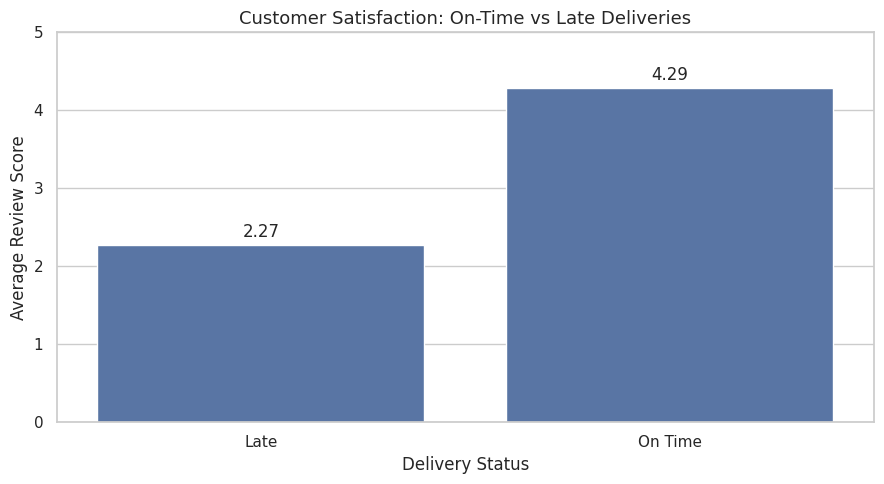

In [31]:

# STEP 4: VISUALISE DELIVERY AND CUSTOMER SATISFACTION

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=delivery_satisfaction,
    x='delivery_status',
    y='Average_Review_Score'
)

plt.title(
    'Customer Satisfaction: On-Time vs Late Deliveries',
    fontsize=13
)

plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')

plt.ylim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()


## 21. Sales and Revenue Analysis

This section examines sales performance using the Order Items and Orders datasets.

The analysis focuses on item prices, freight values, order volumes and revenue trends. It aims to identify the overall sales contribution of product transactions and understand how revenue changes over time.

Revenue figures are presented in Brazilian reais (BRL), reflecting the currency context of the Brazilian e-commerce dataset.

In [32]:

# SALES AND REVENUE ANALYSIS
# Verify dataset columns before analysis

print("ORDER ITEMS COLUMNS")
print(order_items.columns.tolist())

print("\nPAYMENTS COLUMNS")
print(payments.columns.tolist())

print("\nORDERS COLUMNS")
print(orders.columns.tolist())

print("\nORDER ITEMS SAMPLE")
display(order_items.head())

print("\nPAYMENTS SAMPLE")
display(payments.head())


ORDER ITEMS COLUMNS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS COLUMNS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

ORDERS COLUMNS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER ITEMS SAMPLE


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



PAYMENTS SAMPLE


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### 21.1 Overall Sales and Revenue Performance

The overall sales performance is evaluated by examining the total value of product items, freight charges, number of distinct orders and average order value.

The item-price total represents the sum of recorded product prices across the available order item records. Freight value is examined separately to avoid combining different transaction components without a clear definition.

These measures provide an overview of the scale and value of recorded transactions.

In [71]:
# OVERALL SALES AND REVENUE PERFORMANCE

# Calculate overall sales metrics
total_revenue = order_items['price'].sum()
total_freight = order_items['freight_value'].sum()
total_orders = order_items['order_id'].nunique()
total_items_sold = len(order_items)

average_order_value = total_revenue / total_orders

# Display results
print("OVERALL SALES PERFORMANCE")
print("=" * 50)

print(f"Total Item Revenue: R${total_revenue:,.2f}")
print(f"Total Freight Value: R${total_freight:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Items Sold: {total_items_sold:,}")
print(f"Average Item Revenue per Order: R${average_order_value:,.2f}")

OVERALL SALES PERFORMANCE
Total Item Revenue: R$13,591,643.70
Total Freight Value: R$2,251,909.54
Total Orders: 98,666
Total Items Sold: 112,650
Average Item Revenue per Order: R$137.75


### 21.2 Monthly Revenue Analysis

Monthly revenue is examined to understand changes in sales performance over the available observation period.

Order purchase timestamps are used to assign transactions to calendar months, while item prices are aggregated to calculate monthly product sales value.

The analysis helps identify periods of higher and lower sales activity. Incomplete periods should be considered when interpreting the final months of the dataset.

In [72]:
# MONTHLY REVENUE ANALYSIS

# Convert purchase timestamp to datetime
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# Extract month and year
orders['YearMonth'] = (
    orders['order_purchase_timestamp'].dt.to_period('M')
)

# Merge orders with order items
sales_data = order_items.merge(
    orders[['order_id', 'YearMonth']],
    on='order_id',
    how='inner'
)

# Calculate monthly item revenue
monthly_revenue = (
    sales_data.groupby('YearMonth')['price']
    .sum()
    .reset_index()
)

monthly_revenue.columns = ['Month', 'Revenue']

# Display monthly revenue
print("MONTHLY REVENUE PERFORMANCE")
print("=" * 50)

monthly_revenue_display = monthly_revenue.copy()

monthly_revenue_display['Revenue'] = (
    monthly_revenue_display['Revenue']
    .apply(lambda x: f"R${x:,.2f}")
)

display(monthly_revenue_display)

MONTHLY REVENUE PERFORMANCE


,Month,Revenue
0,2016-09,R$267.36
1,2016-10,"R$49,507.66"
2,2016-12,R$10.90
3,2017-01,"R$120,312.87"
4,2017-02,"R$247,303.02"
5,2017-03,"R$374,344.30"
6,2017-04,"R$359,927.23"
7,2017-05,"R$506,071.14"
8,2017-06,"R$433,038.60"
9,2017-07,"R$498,031.48"


### 21.3 Monthly Revenue Trend Visualization

A line chart is used to present monthly revenue trends across the dataset period.

The visualization provides a clear view of changes in sales value over time and helps identify noticeable peaks, declines and possible seasonal patterns.

The interpretation considers the completeness of the observation period, particularly where the final month may contain only partial records.

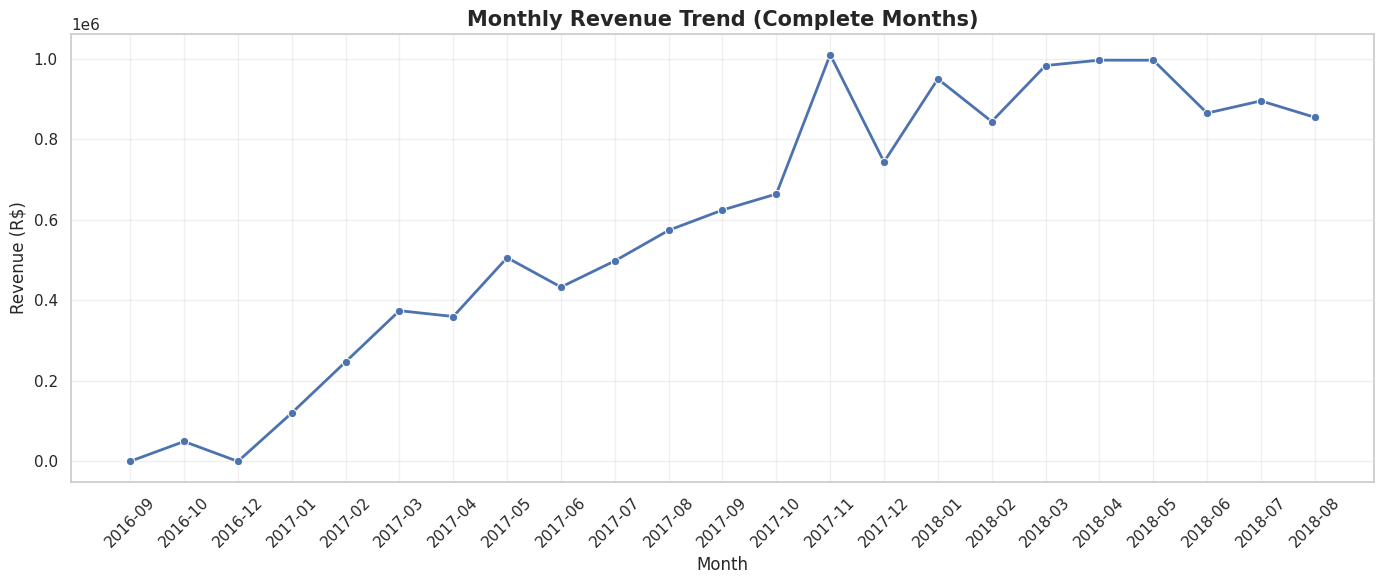

In [77]:
# MONTHLY REVENUE TREND VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

# Exclude the final incomplete month from the trend visualization
complete_monthly_revenue = monthly_revenue[
    monthly_revenue['Month'] < monthly_revenue['Month'].max()
].copy()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=complete_monthly_revenue,
    x=complete_monthly_revenue['Month'].astype(str),
    y='Revenue',
    marker='o',
    linewidth=2
)

plt.title(
    'Monthly Revenue Trend (Complete Months)',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Revenue (R$)')

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 22. Product Category Performance Analysis

This section examines product category performance by combining order item records with product information and the category translation dataset.

The category translation table is used to make product category names easier to interpret by presenting them in English.

This analysis provides the foundation for comparing sales contributions across different product categories.

In [36]:

# CHECK PRODUCT DATASET AND CATEGORY COLUMNS

for name in ['products', 'product_category_translation',
             'category_translation']:
    if name in globals():
        print(f"\n{name.upper()} COLUMNS:")
        print(globals()[name].columns.tolist())
    else:
        print(f"\n{name}: Not currently loaded")



PRODUCTS COLUMNS:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

product_category_translation: Not currently loaded

CATEGORY_TRANSLATION COLUMNS:
['product_category_name', 'product_category_name_english']


### 22.1 Product Category Revenue Analysis

Revenue is aggregated by product category to evaluate the financial contribution of different product groups.

The analysis also considers the number of items sold and the number of distinct orders associated with each category.

These measures provide a broader understanding of category performance beyond revenue alone.

In [74]:
# PRODUCT CATEGORY REVENUE ANALYSIS

# Merge products with English category translations
products_english = products.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

# Merge order items with product categories
category_sales = order_items.merge(
    products_english[
        ['product_id', 'product_category_name_english']
    ],
    on='product_id',
    how='left'
)

# Calculate revenue by product category
category_revenue = (
    category_sales
    .groupby('product_category_name_english')
    .agg(
        Total_Revenue=('price', 'sum'),
        Items_Sold=('order_item_id', 'count'),
        Total_Orders=('order_id', 'nunique')
    )
    .reset_index()
)

# Sort categories by revenue
category_revenue = category_revenue.sort_values(
    by='Total_Revenue',
    ascending=False
)

# Display top 10 categories
print("TOP 10 PRODUCT CATEGORIES BY REVENUE")
print("=" * 55)

display(category_revenue.head(10).round(2))

# Display bottom 10 categories
print("\nBOTTOM 10 PRODUCT CATEGORIES BY REVENUE")
print("=" * 55)

display(category_revenue.tail(10).round(2))

TOP 10 PRODUCT CATEGORIES BY REVENUE


,product_category_name_english,Total_Revenue,Items_Sold,Total_Orders
43,health_beauty,1258681.34,9670,8836
70,watches_gifts,1205005.68,5991,5624
7,bed_bath_table,1036988.68,11115,9417
65,sports_leisure,988048.97,8641,7720
15,computers_accessories,911954.32,7827,6689
39,furniture_decor,729762.49,8334,6449
20,cool_stuff,635290.85,3796,3632
49,housewares,632248.66,6964,5884
5,auto,592720.11,4235,3897
42,garden_tools,485256.46,4347,3518



BOTTOM 10 PRODUCT CATEGORIES BY REVENUE


,product_category_name_english,Total_Revenue,Items_Sold,Total_Orders
27,fashio_female_clothing,2803.64,48,39
32,fashion_sport,2119.51,30,27
52,la_cuisine,2054.99,14,13
3,arts_and_craftmanship,1814.01,24,23
23,diapers_and_hygiene,1567.59,39,27
35,flowers,1110.04,33,29
46,home_comfort_2,760.27,30,24
11,cds_dvds_musicals,730.00,14,12
29,fashion_childrens_clothes,569.85,8,8
61,security_and_services,283.29,2,2


### 22.2 Top 10 Product Categories by Revenue

The ten highest-performing product categories are identified based on their total recorded item-price revenue.

A horizontal bar chart is used to compare their contributions and make the differences in category performance easier to understand.

The results can help highlight important product groups that contribute significantly to the marketplace's recorded sales value.

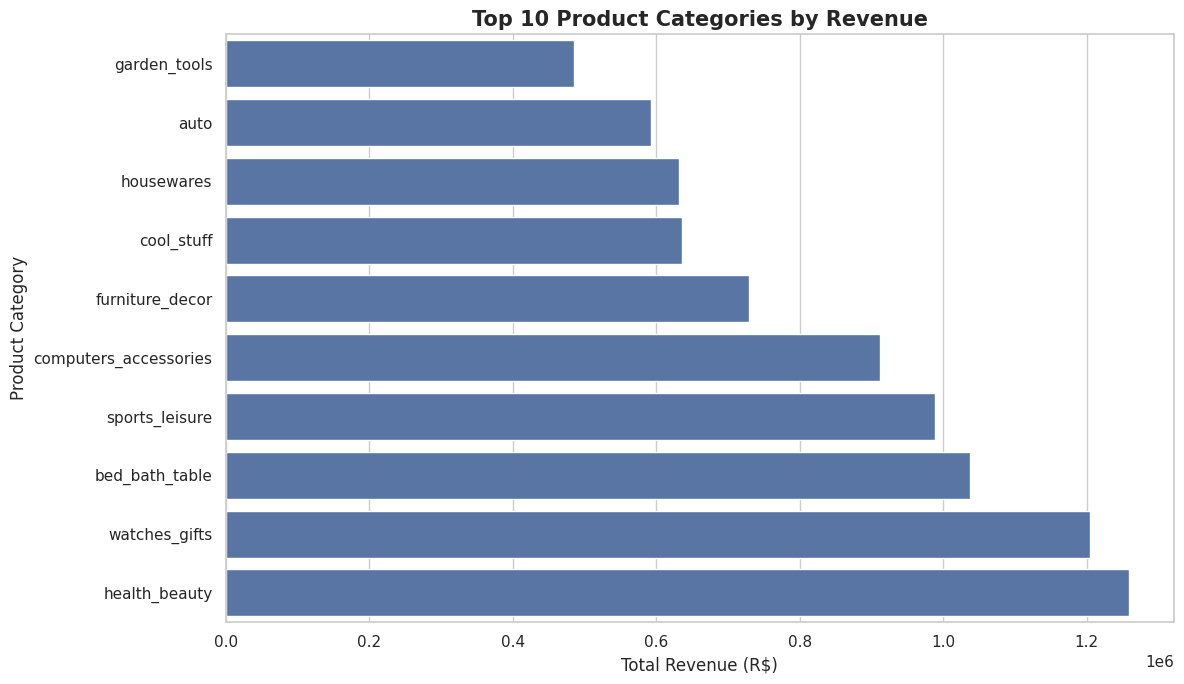

In [75]:
# TOP 10 PRODUCT CATEGORIES BY REVENUE

# Select the top 10 categories
top_10_categories = category_revenue.head(10).sort_values(
    by='Total_Revenue',
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_categories,
    x='Total_Revenue',
    y='product_category_name_english'
)

plt.title(
    'Top 10 Product Categories by Revenue',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Total Revenue (R$)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

## 23. Payment Method Analysis

This section investigates customer payment preferences using the Order Payments dataset.

Payment methods are compared based on transaction counts, total recorded payment value, average payment value and their percentage contribution to the recorded transactions.

The analysis provides insight into how customers complete purchases and which payment methods account for the largest share of payment activity.

In [76]:
# PAYMENT METHOD ANALYSIS

# Group payment records by payment method
payment_analysis = (
    payments
    .groupby('payment_type')
    .agg(
        Total_Payment_Records=('order_id', 'count'),
        Unique_Orders=('order_id', 'nunique'),
        Total_Payment_Value=('payment_value', 'sum'),
        Average_Payment_Value=('payment_value', 'mean')
    )
    .reset_index()
)

# Calculate percentage contribution by payment records
payment_analysis['Payment_Record_Percentage'] = (
    payment_analysis['Total_Payment_Records'] /
    payment_analysis['Total_Payment_Records'].sum() * 100
).round(2)

# Sort by total payment value
payment_analysis = payment_analysis.sort_values(
    by='Total_Payment_Value',
    ascending=False
)

# Display results
print("PAYMENT METHOD PERFORMANCE")
print("=" * 60)

display(payment_analysis.round(2))

PAYMENT METHOD PERFORMANCE


,payment_type,Total_Payment_Records,Unique_Orders,Total_Payment_Value,Average_Payment_Value,Payment_Record_Percentage
1,credit_card,76795,76505,12542084.19,163.32,73.92
0,boleto,19784,19784,2869361.27,145.03,19.04
4,voucher,5775,3866,379436.87,65.70,5.56
2,debit_card,1529,1528,217989.79,142.57,1.47
3,not_defined,3,3,0.00,0.00,0.00


## 24. Final EDA Dataset Validation

A final dataset inventory is used to review the original datasets and the intermediate DataFrames created during the analysis.

This validation provides a summary of the data structures used throughout the project and helps distinguish the nine source datasets from the additional tables generated during data preparation and analysis.

The inventory supports transparency and makes it easier to trace the datasets used in the subsequent sentiment analysis.

In [40]:

# ==========================================
# FINAL EDA VALIDATION: DATASET INVENTORY
# ==========================================

import pandas as pd

print("OLIST E-COMMERCE DATASET INVENTORY")
print("=" * 65)

# Identify all loaded DataFrames
dataframes = {
    name: obj
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

for name, df in dataframes.items():
    print(f"\nDATASET: {name}")
    print("-" * 50)
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")
    print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print("Column Names:")
    print(list(df.columns))

print("\n" + "=" * 65)
print(f"TOTAL DATAFRAMES IDENTIFIED: {len(dataframes)}")


OLIST E-COMMERCE DATASET INVENTORY

DATASET: customers
--------------------------------------------------
Rows: 99,441
Columns: 5
Memory Usage: 26.59 MB
Column Names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

DATASET: orders
--------------------------------------------------
Rows: 99,441
Columns: 9
Memory Usage: 36.73 MB
Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'YearMonth']

DATASET: order_items
--------------------------------------------------
Rows: 112,650
Columns: 7
Memory Usage: 35.99 MB
Column Names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

DATASET: payments
--------------------------------------------------
Rows: 103,886
Columns: 5
Memory Usage: 16.23 MB
Column Names:
['order_id', 'payment_sequ

## 25. Customer Review Sentiment Analysis

This section applies Natural Language Processing (NLP) techniques to analyse the written comments provided by Olist customers.

The objective is to classify customer feedback into positive, neutral and negative sentiment categories to gain additional insight into customer opinions beyond numerical review scores.

Because the dataset contains Brazilian Portuguese customer comments, a Portuguese-language sentiment analysis model is used to process the written reviews.

In [41]:

!pip install pysentimiento -q


### 25.1 Sentiment Model Initialization

The PySentimiento library is used to create a sentiment analysis model configured for the Portuguese language.

The model identifies the sentiment expressed in written customer comments and returns one of three broad categories: positive, neutral or negative.

This approach allows the analysis to account for the language of the original customer feedback.

In [42]:

from pysentimiento import create_analyzer

# Initialise the Portuguese sentiment analyser
sentiment_analyzer = create_analyzer(
    task="sentiment",
    lang="pt"
)

print("Portuguese sentiment analyser initialized successfully!")


config.json:   0%|          | 0.00/952 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/562 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/799k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Portuguese sentiment analyser initialized successfully!


### 25.2 Review Selection and Initial Testing

Customer reviews containing usable written messages are selected for sentiment analysis.

Empty or unavailable comments are excluded because they do not provide text that can be meaningfully classified.

A small sample of comments is initially selected to inspect the input data and prepare it for model testing.

In [43]:

# Select customer reviews that contain written comments
review_samples = reviews[
    reviews["review_comment_message"].notna()
    & (reviews["review_comment_message"].str.strip() != "")
]

# Display five actual customer comments
display(
    review_samples[["review_score", "review_comment_message"]].head(5)
)

print("Total reviews with written comments:", len(review_samples))


,review_score,review_comment_message
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela I...
9,4,aparelho eficiente. no site a marca do aparelh...
12,4,"Mas um pouco ,travando...pelo valor ta Boa.\r\n"
15,5,"Vendedor confiável, produto ok e entrega antes..."


Total reviews with written comments: 40950


### 25.3 Sentiment Prediction Testing

A small sample of customer comments is processed using the sentiment analysis model to examine how the model classifies written feedback.

The predicted sentiment categories are inspected alongside the original comments to confirm that the model produces usable outputs before processing the larger dataset.

In [44]:

# Select five customer comments for testing
test_comments = review_samples[
    "review_comment_message"
].head(5).tolist()

# Analyse the sentiment of each comment
for comment in test_comments:
    result = sentiment_analyzer.predict(comment)

    print("Customer Review:", comment)
    print("Predicted Sentiment:", result.output)
    print("Confidence Scores:", result.probas)
    print("-" * 60)


Customer Review: Recebi bem antes do prazo estipulado.
Predicted Sentiment: NEU
Confidence Scores: {'NEG': 0.05130644515156746, 'NEU': 0.8656340837478638, 'POS': 0.08305946737527847}
------------------------------------------------------------
Customer Review: Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa
Predicted Sentiment: POS
Confidence Scores: {'NEG': 0.002244128379970789, 'NEU': 0.008621188811957836, 'POS': 0.989134669303894}
------------------------------------------------------------
Customer Review: aparelho eficiente. no site a marca do aparelho esta impresso como 3desinfector e ao chegar esta com outro nome...atualizar com a marca correta uma vez que é o mesmo aparelho
Predicted Sentiment: NEG
Confidence Scores: {'NEG': 0.637627363204956, 'NEU': 0.32227978110313416, 'POS': 0.04009280353784561}
------------------------------------------------------------
Customer Review: Mas um pouco ,travando...pelo valor ta Boa.

Predic

### 25.4 Sentiment Validation Sample

A random sample of customer reviews is selected for an additional inspection of sentiment predictions.

This provides an opportunity to examine the model's output across different customer comments and assess whether the predictions are suitable for the full analysis.

In [45]:

# Select 20 random reviews for validation
validation_sample = review_samples[
    ["review_score", "review_comment_message"]
].sample(n=20, random_state=42)

# Predict sentiment and compare with review scores
validation_sample = validation_sample.copy()

validation_sample["Text_Sentiment"] = validation_sample[
    "review_comment_message"
].apply(lambda comment: sentiment_analyzer.predict(comment).output)

# Display the comparison
display(validation_sample)


,review_score,review_comment_message,Text_Sentiment
18036,5,SEM QUEIXAS,NEU
89184,4,Produto chegou conforme descrito e antes do pr...,NEU
74375,3,demora na entrega. e produto pesado demais,NEG
31028,5,Fui muiro bem atendido.,POS
33213,5,Muito bom,POS
13053,5,produto entregue no prazo e muito bem embalado...,POS
46896,5,A LOJA É MUITO CONFIÁVEL E ATENCIOSA.,POS
62557,5,"Excelente, recebi um dia antes do prazo e muit...",POS
87537,2,"oi e como fica o produto,que ate agora não che...",NEG
86992,5,Recomendo,POS


### 25.5 Sentiment Model Inspection and Batch Testing

The model's prediction methods and output structure are inspected to understand how sentiment results are returned.

Batch prediction is tested to confirm that multiple customer comments can be processed efficiently. This prepares the analysis for processing the full collection of written reviews.

In [46]:
# Inspect the sentiment analyser's available prediction methods
print("Analyser type:", type(sentiment_analyzer))
print("Prediction method:", sentiment_analyzer.predict)
print("Available batch methods:", [
    method for method in dir(sentiment_analyzer)
    if "batch" in method.lower() or "many" in method.lower()
])

Analyser type: <class 'pysentimiento.analyzer.AnalyzerForSequenceClassification'>
Prediction method: <bound method AnalyzerForSequenceClassification.predict of <pysentimiento.analyzer.AnalyzerForSequenceClassification object at 0x7be40ac06cf0>>
Available batch methods: ['batch_size']


In [47]:
import inspect

print(inspect.signature(sentiment_analyzer.predict))

(inputs, context=None, target=None, preprocess_context=True)


In [48]:
# Test sentiment prediction on 5 customer reviews
test_comments = review_samples["review_comment_message"].head(5).tolist()

batch_results = sentiment_analyzer.predict(test_comments)

print("Result type:", type(batch_results))
print("Number of results:", len(batch_results))

for comment, result in zip(test_comments, batch_results):
    print("\nReview:", comment)
    print("Predicted sentiment:", result.output)

Map:   0%|          | 0/5 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Result type: <class 'list'>
Number of results: 5

Review: Recebi bem antes do prazo estipulado.
Predicted sentiment: NEU

Review: Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa
Predicted sentiment: POS

Review: aparelho eficiente. no site a marca do aparelho esta impresso como 3desinfector e ao chegar esta com outro nome...atualizar com a marca correta uma vez que é o mesmo aparelho
Predicted sentiment: NEG

Review: Mas um pouco ,travando...pelo valor ta Boa.

Predicted sentiment: NEG

Review: Vendedor confiável, produto ok e entrega antes do prazo.
Predicted sentiment: NEU


In [49]:
# Inspect the current sentiment analysis progress

print("REVIEWS DATASET")
print("Shape:", reviews.shape)
print("Columns:", reviews.columns.tolist())

print("\nREVIEWS WITH WRITTEN COMMENTS")
print("Total:", len(review_samples))

print("\nEXISTING SENTIMENT COLUMNS")

for column in ["Sentiment_Category", "Text_Sentiment"]:
    if column in reviews.columns:
        print(f"\n{column}:")
        print(reviews[column].value_counts(dropna=False))
    else:
        print(f"{column}: Not found in reviews")

REVIEWS DATASET
Shape: (99224, 9)
Columns: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'Comment_Availability', 'Sentiment_Category']

REVIEWS WITH WRITTEN COMMENTS
Total: 40950

EXISTING SENTIMENT COLUMNS

Sentiment_Category:
Sentiment_Category
Positive    76470
Negative    14575
Neutral      8179
Name: count, dtype: int64
Text_Sentiment: Not found in reviews


### 25.6 Full Customer Review Sentiment Classification

The sentiment model is applied to all selected customer reviews containing written comments.

To manage processing efficiently, the comments are analysed in batches rather than being submitted as one large request.

The resulting sentiment predictions are stored in a separate column, `Text_Sentiment`, within the Reviews dataset. Reviews without usable written comments remain unclassified in this text-based analysis.

In [50]:

# FULL CUSTOMER REVIEW TEXT SENTIMENT ANALYSIS

from tqdm.auto import tqdm

# Collect all written customer comments
text_comments = review_samples["review_comment_message"].tolist()

# Store model predictions
predicted_sentiments = []

# Process comments in batches
batch_size = 128

for start in tqdm(range(0, len(text_comments), batch_size)):
    batch = text_comments[start:start + batch_size]

    batch_results = sentiment_analyzer.predict(batch)

    predicted_sentiments.extend(
        [result.output for result in batch_results]
    )

# Create a separate column for NLP sentiment predictions
reviews["Text_Sentiment"] = np.nan

reviews.loc[
    review_samples.index, "Text_Sentiment"
] = predicted_sentiments

# Display the sentiment distribution
print("TEXT-BASED SENTIMENT DISTRIBUTION")
print("=" * 50)

display(
    reviews["Text_Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Total_Reviews")
)


  0%|          | 0/320 [00:00<?, ?it/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Map:   0%|          | 0/128 [00:00<?, ? examples/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

... (315 outputs left out)

Map:   0%|          | 0/118 [00:00<?, ? examples/s]

TEXT-BASED SENTIMENT DISTRIBUTION


/tmp/ipykernel_1535/513211712.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['NEU', 'POS', 'NEG', 'NEG', 'NEU', 'NEG', 'NEG', 'POS', 'NEU', 'NEU', 'POS', 'NEG', 'NEG', 'POS', 'POS', 'POS', 'POS', 'NEG', 'POS', 'POS', 'NEU', 'NEU', 'NEG', 'NEU', 'POS', 'POS', 'POS', 'POS', 'POS', 'NEG', 'POS', 'NEG', 'NEU', 'NEG', 'POS', 'POS', 'NEU', 'POS', 'NEG', 'NEU', 'POS', 'POS', 'POS', 'NEU', 'POS', 'NEU', 'POS', 'NEU', 'POS', 'POS', 'NEG', 'POS', 'NEU', 'NEG', 'POS', 'POS', 'POS', 'POS', 'NEU', 'NEG', 'NEU', 'POS', 'POS', 'POS', 'NEU', 'POS', 'NEG', 'NEG', 'NEG', 'NEG', 'NEG', 'POS', 'POS', 'NEU', 'POS', 'POS', 'POS', 'NEG', 'POS', 'NEU', 'POS', 'NEU', 'NEU', 'NEG', 'NEG', 'POS', 'NEG', 'POS', 'NEU', 'NEG', 'NEG', 'POS', 'POS', 'POS', 'POS', 'NEU', 'POS', 'NEU', 'NEG', 'POS', 'NEG', 'NEU', 'POS', 'NEU', 'NEG', 'POS', 'POS', 'POS', 'NEG', 'POS', 'POS', 'NEU', 'POS', 'NEU', 'NEU', 'NEG', 'NEG', 'POS', 'POS', 

,Sentiment,Total_Reviews
0,POS,19353
1,NEU,13703
2,NEG,7894


### 25.7 Sentiment Comparison with Customer Review Scores

The predicted text sentiment is compared with broad sentiment categories derived from numerical customer review scores.

For this comparison, ratings of 1 and 2 are grouped as negative, a rating of 3 as neutral, and ratings of 4 and 5 as positive.

A cross-tabulation is used to examine how the model's predictions correspond with the rating-based categories. This comparison provides an indication of alignment between written feedback and numerical ratings.

In [51]:

# Validate predicted sentiment against customer review scores

sentiment_validation = reviews.loc[
    reviews["Text_Sentiment"].notna()
    & reviews["review_comment_message"].notna()
    & (reviews["review_comment_message"].str.strip() != ""),
    ["review_score", "Text_Sentiment"]
].copy()

# Convert star ratings into broad sentiment categories
sentiment_validation["Score_Based_Sentiment"] = (
    sentiment_validation["review_score"].map({
        1: "NEG",
        2: "NEG",
        3: "NEU",
        4: "POS",
        5: "POS"
    })
)

# Compare model predictions with rating-based sentiment
comparison = pd.crosstab(
    sentiment_validation["Score_Based_Sentiment"],
    sentiment_validation["Text_Sentiment"],
    margins=True
)

display(comparison)

print("Reviews included in validation:", len(sentiment_validation))


Text_Sentiment,NEG,NEU,POS,All
Score_Based_Sentiment,,,,
NEG,5826,4849,214,10889
NEU,1094,1826,636,3556
POS,974,7028,18503,26505
All,7894,13703,19353,40950


Reviews included in validation: 40950


### 25.8 Sentiment Agreement Analysis

The distribution of model predictions within each rating-based sentiment category is calculated as a percentage.

This makes it easier to understand how frequently the model predicts positive, neutral or negative sentiment for reviews belonging to each rating-based group.

The percentage comparison provides additional detail beyond the raw counts shown in the cross-tabulation.

In [52]:

# Calculate percentage agreement within each rating-based category

comparison_percent = pd.crosstab(
    sentiment_validation["Score_Based_Sentiment"],
    sentiment_validation["Text_Sentiment"],
    normalize="index"
) * 100

display(comparison_percent.round(2))


Text_Sentiment,NEG,NEU,POS
Score_Based_Sentiment,,,
NEG,53.50,44.53,1.97
NEU,30.76,51.35,17.89
POS,3.67,26.52,69.81


In [53]:

# Calculate percentage agreement within each rating-based category

comparison_percent = pd.crosstab(
    sentiment_validation["Score_Based_Sentiment"],
    sentiment_validation["Text_Sentiment"],
    normalize="index"
) * 100

display(comparison_percent.round(2))


Text_Sentiment,NEG,NEU,POS
Score_Based_Sentiment,,,
NEG,53.50,44.53,1.97
NEU,30.76,51.35,17.89
POS,3.67,26.52,69.81


### 25.9 Sentiment Validation Visualization

A heatmap is used to visualize the percentage distribution of model-predicted sentiment across the rating-based sentiment categories.

The visualization makes areas of agreement and disagreement easier to identify and provides a clear summary of the relationship between written-comment sentiment and numerical review ratings.

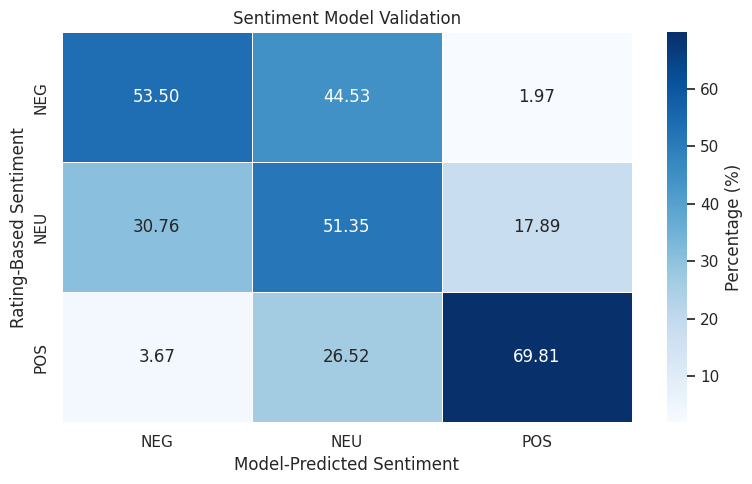

In [54]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.heatmap(
    comparison_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Sentiment Model Validation")
plt.xlabel("Model-Predicted Sentiment")
plt.ylabel("Rating-Based Sentiment")

plt.tight_layout()
plt.show()


### 25.10 Distribution of Predicted Customer Sentiment

The distribution of predicted sentiment categories is visualized to understand the overall tone of the written customer feedback.

The chart compares the number of positive, neutral and negative predictions among reviews that contain usable written comments.

The results provide an overview of the sentiment patterns identified by the Portuguese-language NLP model.

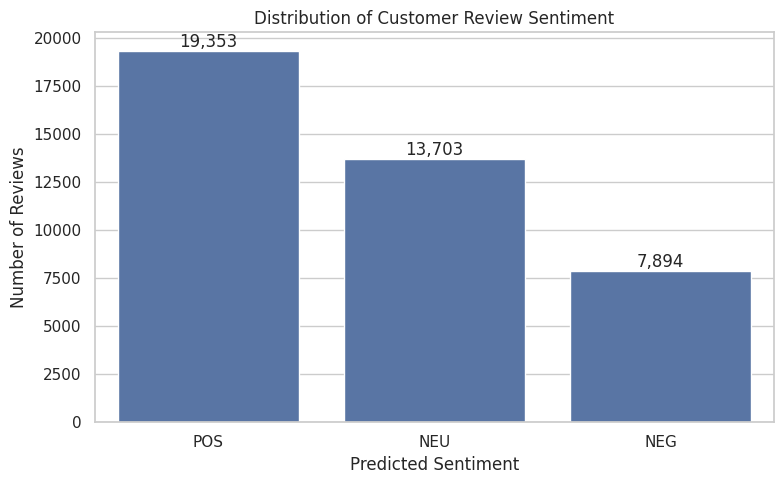

In [55]:

# Visualize the distribution of predicted customer sentiment

sentiment_counts = reviews["Text_Sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Distribution of Customer Review Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Reviews")

for i, value in enumerate(sentiment_counts.values):
    plt.text(i, value + 200, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()


### 25.11 Sentiment Model Evaluation

The sentiment predictions are evaluated against the broad sentiment categories derived from customer review scores.

Overall agreement and a classification report are used to examine how closely the model's predictions correspond with the rating-based labels.

It is important to note that numerical review scores are used as a reference for comparison, not as independently verified ground-truth sentiment labels. Therefore, the reported agreement and classification metrics should not be interpreted as definitive measures of the model's true accuracy.

In [56]:
from sklearn.metrics import accuracy_score, classification_report

# Compare model predictions with rating-based sentiment labels
y_true = sentiment_validation["Score_Based_Sentiment"]
y_pred = sentiment_validation["Text_Sentiment"]

# Calculate overall agreement
accuracy = accuracy_score(y_true, y_pred)

print("SENTIMENT MODEL EVALUATION")
print("=" * 40)
print(f"Overall Agreement: {accuracy * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=" * 40)

print(classification_report(
    y_true,
    y_pred,
    labels=["NEG", "NEU", "POS"],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

SENTIMENT MODEL EVALUATION
Overall Agreement: 63.87%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.74      0.54      0.62     10889
     Neutral       0.13      0.51      0.21      3556
    Positive       0.96      0.70      0.81     26505

    accuracy                           0.64     40950
   macro avg       0.61      0.58      0.55     40950
weighted avg       0.83      0.64      0.71     40950



### 25.12 Sentiment Data Type Validation

The sentiment prediction column is checked to ensure that its data type is suitable for storing categorical sentiment labels and missing values.

This validation helps maintain consistency in the Reviews dataset and supports reliable use of the sentiment results in subsequent analysis.

In [57]:
# Clean up the sentiment prediction column's data type

reviews["Text_Sentiment"] = reviews["Text_Sentiment"].astype("object")

print("Sentiment column data type:", reviews["Text_Sentiment"].dtype)
print("\nSentiment distribution:")
print(reviews["Text_Sentiment"].value_counts(dropna=False))

Sentiment column data type: object

Sentiment distribution:
Text_Sentiment
NaN    58274
POS    19353
NEU    13703
NEG     7894
Name: count, dtype: int64


## 26. Delivery Data Quality Reconciliation

A reconciliation is performed to validate the records included in the delivery performance analysis.

The number of orders marked as delivered is compared with the number of records retained after applying the delivery date requirements.

The analysis also identifies missing delivery-related timestamps and documents the records excluded from the delivery calculations. This helps establish the scope and reliability of the delivery dataset used in the customer satisfaction investigation.

In [58]:
# DELIVERY DATA QUALITY RECONCILIATION

print("DELIVERY DATA RECONCILIATION")
print("=" * 50)

total_orders = len(orders)

delivered_status_count = (
    orders["order_status"] == "delivered"
).sum()

valid_delivery_count = len(delivered_orders)

excluded_delivered = (
    delivered_status_count - valid_delivery_count
)

print(f"Total orders: {total_orders:,}")
print(f"Orders marked delivered: {delivered_status_count:,}")
print(f"Delivered orders included in analysis: {valid_delivery_count:,}")
print(f"Delivered orders excluded: {excluded_delivered:,}")

print("\nREASONS FOR EXCLUSION")
print("=" * 50)

print(
    "Missing customer delivery date:",
    orders.loc[
        orders["order_status"] == "delivered",
        "order_delivered_customer_date"
    ].isna().sum()
)

print(
    "Missing estimated delivery date:",
    orders.loc[
        orders["order_status"] == "delivered",
        "order_estimated_delivery_date"
    ].isna().sum()
)

print(
    "Missing purchase timestamp:",
    orders.loc[
        orders["order_status"] == "delivered",
        "order_purchase_timestamp"
    ].isna().sum()
)

DELIVERY DATA RECONCILIATION
Total orders: 99,441
Orders marked delivered: 96,478
Delivered orders included in analysis: 96,470
Delivered orders excluded: 8

REASONS FOR EXCLUSION
Missing customer delivery date: 8
Missing estimated delivery date: 0
Missing purchase timestamp: 0


### 26.1 Delivery and Review Dataset Reconciliation

The delivery dataset is compared with the customer Reviews dataset to examine the structure of the merged records.

The analysis checks the number of rows, unique order IDs and repeated order IDs after merging.

This step is important because an order may have multiple associated review records. Understanding this relationship helps prevent repeated orders from being counted as independent observations in subsequent comparisons.

In [70]:
# CHECK FOR DUPLICATES IN DELIVERY AND REVIEW ANALYSIS

print("DELIVERY AND REVIEW MERGE VALIDATION")
print("=" * 50)

print("Delivery dataset:")
print("Rows:", len(delivered_orders))
print("Unique orders:", delivered_orders["order_id"].nunique())

print("\nReview dataset:")
print("Rows:", len(reviews))
print("Unique orders:", reviews["order_id"].nunique())

print("\nMerged delivery-review dataset:")
print("Rows:", len(delivery_reviews))
print("Unique orders:", delivery_reviews["order_id"].nunique())

print("\nDuplicate order IDs in merged dataset:")
print(delivery_reviews["order_id"].duplicated().sum())

print("\nReview scores by delivery status:")
display(
    delivery_reviews.groupby("delivery_status")["review_score"]
    .agg(["count", "mean"])
    .round(2)
)

DELIVERY AND REVIEW MERGE VALIDATION
Delivery dataset:
Rows: 96470
Unique orders: 96470

Review dataset:
Rows: 99224
Unique orders: 98673

Merged delivery-review dataset:
Rows: 96353
Unique orders: 95824

Duplicate order IDs in merged dataset:
529

Review scores by delivery status:


,count,mean
delivery_status,,
Late,6409,2.27
On Time,89944,4.29


### 26.2 Inspection of Merged Delivery and Review Records

The merged delivery and review dataset is inspected to confirm its available columns and examine sample records.

This step helps verify the structure of the combined dataset and identify the correct column names before carrying out the final order-level analysis.

In [62]:
print("DELIVERY REVIEW COLUMNS")
print(delivery_reviews.columns.tolist())

print("\nSAMPLE MERGED RECORDS")
display(delivery_reviews.head(5))

DELIVERY REVIEW COLUMNS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_days', 'delay_days', 'delivery_status', 'review_score']

SAMPLE MERGED RECORDS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,delivery_status,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-8,On Time,4
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-6,On Time,4
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-18,On Time,5
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-13,On Time,5
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-10,On Time,5


In [65]:
print("DELIVERY REVIEW DATASET COLUMNS")
for column in delivery_reviews.columns:
    print(column)

DELIVERY REVIEW DATASET COLUMNS
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
delivery_days
delay_days
delivery_status
review_score


### 26.3 Order-Level Review Consolidation

To avoid counting the same order multiple times, the merged delivery and review records are consolidated at the order level.

Where multiple reviews are associated with one order, their review scores are aggregated using the mean, while the delivery status is retained for the order.

This produces a dataset with one record per unique order, providing a more appropriate basis for comparing customer satisfaction across delivery categories.

In [67]:

# Correct delivery and review analysis
# First, combine multiple reviews for the same order

order_level_reviews = (
    delivery_reviews
    .groupby("order_id", as_index=False)
    .agg({
        "delivery_status": "first",
        "review_score": "mean"
    })
)

print("UNIQUE ORDER-LEVEL REVIEW ANALYSIS")
print("===================================")
print("Total unique orders:", len(order_level_reviews))

print("\nAverage review score by delivery status:")

delivery_review_summary = (
    order_level_reviews
    .groupby("delivery_status")["review_score"]
    .agg(["count", "mean"])
    .round(2)
)

display(delivery_review_summary)


UNIQUE ORDER-LEVEL REVIEW ANALYSIS
Total unique orders: 95824

Average review score by delivery status:


,count,mean
delivery_status,,
Late,6381,2.27
On Time,89443,4.29


### 26.4 Statistical Test of Delivery Performance and Customer Satisfaction

The Mann–Whitney U test is applied to compare the distribution of customer review scores between orders delivered on time and orders delivered late.

The test is used because it compares two independent groups without requiring the review scores to follow a normal distribution.

A significance level of 0.05 is used to assess whether the observed difference between the two groups is statistically significant.

The result is interpreted as evidence of an association between delivery status and customer review scores, not proof that delivery delays directly cause lower satisfaction.

In [68]:

from scipy.stats import mannwhitneyu

# Separate review scores by delivery status
on_time_scores = order_level_reviews.loc[
    order_level_reviews["delivery_status"] == "On Time",
    "review_score"
]

late_scores = order_level_reviews.loc[
    order_level_reviews["delivery_status"] == "Late",
    "review_score"
]

# Perform Mann-Whitney U test
statistic, p_value = mannwhitneyu(
    on_time_scores,
    late_scores,
    alternative="two-sided"
)

print("STATISTICAL SIGNIFICANCE TEST")
print("=============================")
print(f"Mann-Whitney U Statistic: {statistic:.2f}")
print(f"P-value: {p_value:.10f}")

if p_value < 0.05:
    print("\nConclusion: The difference in review scores is statistically significant.")
else:
    print("\nConclusion: There is insufficient evidence of a statistically significant difference.")


STATISTICAL SIGNIFICANCE TEST
Mann-Whitney U Statistic: 467426830.50
P-value: 0.0000000000

Conclusion: The difference in review scores is statistically significant.


### 26.5 Effect Size and Median Review Score Comparison

In addition to statistical significance, the analysis calculates the median review score for on-time and late deliveries.

A rank-biserial effect size is also calculated to estimate the magnitude and direction of the difference between the two groups.

Considering both the statistical test and effect size provides a more complete interpretation of the relationship between delivery performance and customer satisfaction.

In [69]:

# Calculate effect size and median review scores

n1 = len(on_time_scores)
n2 = len(late_scores)

# Rank-biserial correlation
effect_size = (2 * statistic / (n1 * n2)) - 1

print("EFFECT SIZE AND SCORE COMPARISON")
print("================================")
print(f"On-time median score: {on_time_scores.median():.2f}")
print(f"Late median score: {late_scores.median():.2f}")
print(f"Rank-biserial effect size: {effect_size:.4f}")

print("\nInterpretation:")
print("A positive effect size indicates higher review scores for on-time deliveries.")


EFFECT SIZE AND SCORE COMPARISON
On-time median score: 5.00
Late median score: 1.00
Rank-biserial effect size: 0.6380

Interpretation:
A positive effect size indicates higher review scores for on-time deliveries.


## 27. Key Findings and Business Insights

The analysis provides insights into several important areas of Olist's e-commerce operations.

**Customer Reviews and Satisfaction**

Customer review scores provide an overview of customer satisfaction, while the sentiment analysis offers additional insight into the tone of written feedback. The comparison between numerical ratings and text-based sentiment also highlights the differences that can occur between rating-based and language-based assessments.

**Delivery Performance**

The delivery analysis compares on-time and late orders and examines their associated customer review scores. The statistical test and effect size provide evidence about the strength of the relationship between delivery performance and customer satisfaction.

**Sales and Product Category Performance**

The revenue analysis identifies overall item-price value, monthly sales patterns and the product categories contributing the highest recorded revenue.

**Payment Preferences**

The payment analysis highlights the distribution of transaction activity across the available payment methods.

Together, these findings provide a broader understanding of customer experience, sales performance and operational efficiency within the Olist marketplace.

## 28. Business Recommendations

Based on the analytical findings, the following recommendations can support improved marketplace performance:

1. **Improve Delivery Reliability:** Monitor late deliveries and investigate operational factors contributing to delays. Improving delivery consistency may help strengthen customer satisfaction.

2. **Monitor Customer Feedback:** Regularly analyse numerical ratings and written comments to identify recurring complaints, customer expectations and areas requiring improvement.

3. **Strengthen Product Category Performance:** Use category-level revenue and order information to identify high-performing product groups and evaluate opportunities to improve weaker categories.

4. **Review Payment Preferences:** Monitor customer payment behaviour to ensure that commonly used payment methods remain reliable and convenient.

5. **Use Sentiment Analysis for Customer Insights:** Incorporate text-based sentiment monitoring into customer feedback analysis while recognizing that automated predictions should be interpreted alongside review scores and other customer experience indicators.

These recommendations are intended to support data-informed decisions across customer experience, sales and marketplace operations.

## 29. Conclusion

This project applied Exploratory Data Analysis, Data Visualization and Natural Language Processing techniques to the Brazilian E-Commerce Public Dataset by Olist.

Using Python and its analytical libraries, the project examined data quality, customer reviews, delivery performance, sales trends, product category revenue, payment preferences and customer sentiment.

The analysis also applied statistical testing to investigate the relationship between delivery performance and customer satisfaction.

Overall, the project demonstrates how structured data analysis and visualization can transform raw e-commerce records into meaningful business insights. It also highlights the importance of data validation, appropriate analytical methods and careful interpretation when drawing conclusions from real-world datasets.